<a href="https://colab.research.google.com/github/miriamamin1213-ux/AUC_Curves/blob/main/HecktorCNNSHAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 23.0MB/s]


Dataset ready: /content/HPV2025.xlsx
Dataset size (KB): 64.49
Rows available: 588
Predictors: ['Age', 'Gender', 'Tobacco Consumption', 'Alcohol Consumption', 'Performance Status', 'T-stage', 'N-stage', 'M-stage']
SMOTE: False
Target class counts:
HPV_Label
0     58
1    530
Name: count, dtype: int64
Train: 381 rows | class counts: {0: 37, 1: 344}
Validation: 89 rows | class counts: {0: 9, 1: 80}
Test: 118 rows | class counts: {0: 12, 1: 106}
Original predictor count: 8
Encoded feature count: 23
Automatic class weights: [5.14864865 0.55377907]
SMOTE: False
CNNClassifier(
  (conv): Conv1d(1, 16, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=368, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=16, bias=True)
  (fc3): Linear(in_features=16, out_features=2, bias=True)
)
Epoch 001/500 | train loss=0.6897 | val loss=0.7064 | val ROC-AUC=0.4986 | val PR-AUC=0.9026 | val balanced acc

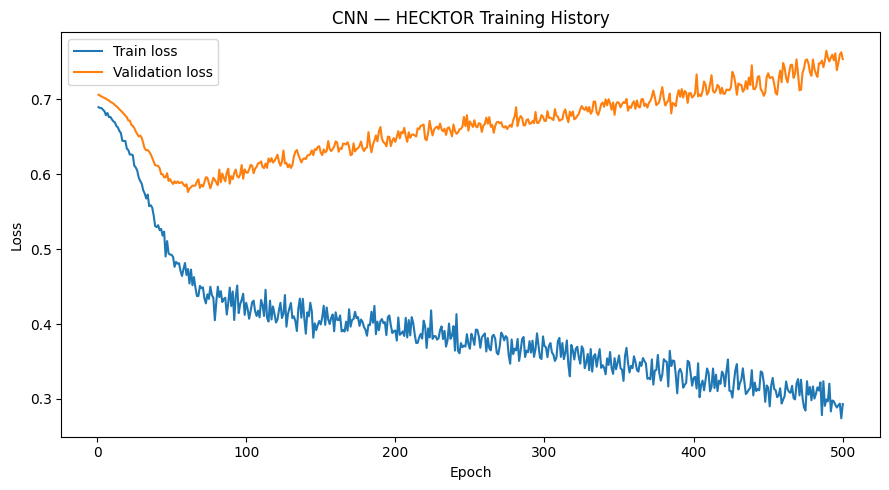


CHECKPOINT: best_val_loss
Epoch: 61
Threshold: 0.595

TEST METRICS
Checkpoint                      best_val_loss
Checkpoint_Epoch                           61
Validation_Loss                       0.57637
Validation_ROC_AUC                   0.786111
Validation_PR_AUC                    0.971892
Validation_Balanced_Accuracy         0.751389
Threshold                               0.595
Accuracy                             0.694915
Balanced_Accuracy                     0.68239
Precision                            0.948718
Recall                               0.698113
F1                                   0.804348
ROC_AUC                              0.756289
PR_AUC                               0.963528

Confusion matrix:
[[ 8  4]
 [32 74]]

Classification report:
              precision    recall  f1-score   support

           0       0.20      0.67      0.31        12
           1       0.95      0.70      0.80       106

    accuracy                           0.69       118
   macro

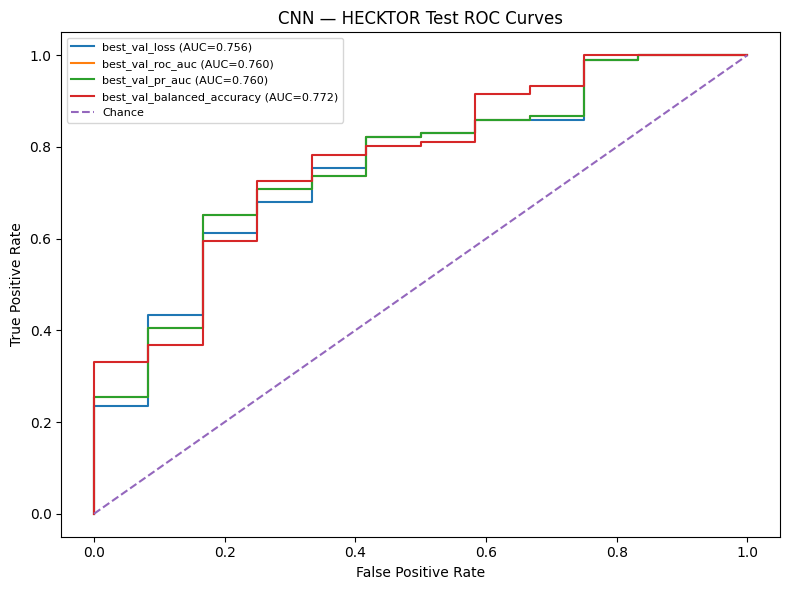

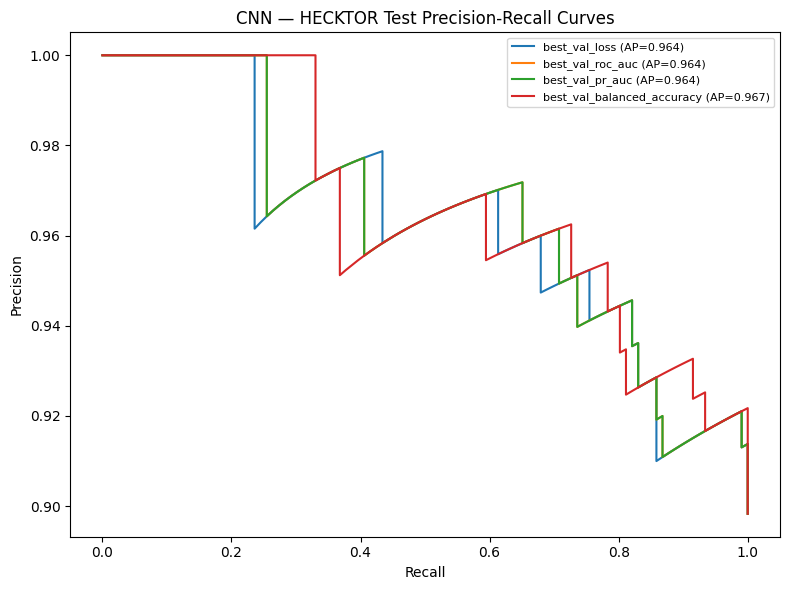


CNN — HECKTOR TEST SET CHECKPOINT COMPARISON
                Checkpoint  Checkpoint_Epoch  Threshold  Accuracy  Balanced_Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC
             best_val_loss                61      0.595  0.694915           0.682390   0.948718 0.698113 0.804348 0.756289 0.963528
          best_val_roc_auc                50      0.580  0.711864           0.728774   0.961538 0.707547 0.815217 0.760220 0.964367
           best_val_pr_auc                50      0.580  0.711864           0.728774   0.961538 0.707547 0.815217 0.760220 0.964367
best_val_balanced_accuracy                27      0.565  0.635593           0.686321   0.956522 0.622642 0.754286 0.772013 0.966603

Saved results to: /content/CNN_results_HECKTOR
Saved checkpoints to: /content/CNN_results_HECKTOR/checkpoints

Output files:
 - CNN_epoch_history.csv
 - CNN_results.csv
 - CNN_test_predictions.csv
 - checkpoint_summary.csv
 - checkpoints
 - cnn_preprocessor.joblib
 - metrics.csv
 - metrics_al

In [1]:
# ============================================================
# CNN — HECKTOR HPV CLASSIFIER
# Hancock-aligned methodology | Seed 42 | No SMOTE
# 8 predictors | 65/15/20 split | 500 epochs
# Four validation-selected checkpoints
# ============================================================

!pip -q install gdown

import os
import json
import random
import copy
import warnings
import joblib
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gdown

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
MAX_EPOCHS = 500
BATCH_SIZE = 32


# ============================================================
# 1. REPRODUCIBILITY AND DEVICE
# ============================================================

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


# ============================================================
# 2. DOWNLOAD AND LOAD HECKTOR DATA
# ============================================================

# Download directly; no Google Drive mount is required.
BASE = "/content"
DATA_PATH = "/content/HPV2025.xlsx"
OUT_DIR = os.path.join(BASE, "CNN_results_HECKTOR")
CHECKPOINT_DIR = os.path.join(OUT_DIR, "checkpoints")

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

FILE_ID = "1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv"

if not os.path.isfile(DATA_PATH):
    print("Downloading HPV2025.xlsx from Google Drive...")

    downloaded = gdown.download(
        id=FILE_ID,
        output=DATA_PATH,
        quiet=False
    )

    if downloaded is None or not os.path.isfile(DATA_PATH):
        raise FileNotFoundError(
            "Could not download HPV2025.xlsx. "
            "Check the Google Drive file ID and sharing permissions."
        )

if not os.path.isfile(DATA_PATH) or os.path.getsize(DATA_PATH) == 0:
    raise FileNotFoundError(
        f"Dataset is missing or empty: {DATA_PATH}"
    )

print("Dataset ready:", DATA_PATH)
print("Dataset size (KB):", round(os.path.getsize(DATA_PATH) / 1024, 2))

df = pd.read_excel(DATA_PATH)

target_col = "HPV Status"

if target_col not in df.columns:
    raise KeyError(
        f"Missing target column '{target_col}'. "
        f"Available columns: {df.columns.tolist()}"
    )

# Remove rows without a target before modelling.
df = df.dropna(subset=[target_col]).copy()

# Preserve patient identifiers for result exports only.
id_col = next(
    (c for c in ["PatientID", "patient_id"] if c in df.columns),
    None
)

if id_col is None:
    patient_ids = pd.Series(
        np.arange(len(df)),
        index=df.index,
        name="patient_id"
    )
else:
    patient_ids = df[id_col].copy()

# Do not use IDs or unrelated task columns as predictors.
df = df.drop(
    columns=[
        "PatientID",
        "patient_id",
        "CenterID",
        "Task 1",
        "Task 2",
        "Task 3"
    ],
    errors="ignore"
)

# The eight specified HECKTOR predictors.
features = [
    "Age",
    "Gender",
    "Tobacco Consumption",
    "Alcohol Consumption",
    "Performance Status",
    "T-stage",
    "N-stage",
    "M-stage"
]

numeric_features = ["Age"]

categorical_features = [
    "Gender",
    "Tobacco Consumption",
    "Alcohol Consumption",
    "Performance Status",
    "T-stage",
    "N-stage",
    "M-stage"
]

missing_features = [
    col for col in features if col not in df.columns
]

if missing_features:
    raise KeyError(
        f"Missing predictor columns: {missing_features}\n"
        f"Available columns: {df.columns.tolist()}"
    )


# ------------------------------------------------------------
# Normalize HPV Status to binary labels: negative=0, positive=1
# ------------------------------------------------------------

def normalize_label(value):
    if pd.isna(value):
        return np.nan

    value_str = str(value).strip().lower()

    if value_str in {
        "negative", "neg", "0", "0.0", "false", "no"
    }:
        return 0

    if value_str in {
        "positive", "pos", "1", "1.0", "true", "yes"
    }:
        return 1

    try:
        number = float(value_str)
        if number in (0.0, 1.0):
            return int(number)
    except (ValueError, TypeError):
        pass

    return np.nan


df["HPV_Label"] = df[target_col].map(normalize_label)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

if df["HPV_Label"].nunique() != 2:
    raise ValueError(
        "HPV Status must contain both classes, 0 and 1, "
        "after label normalization."
    )

# Identifiers are retained for output but never enter the model.
df = df[features + ["HPV_Label"]].copy()
df["patient_id"] = patient_ids.reindex(df.index).values

print("Rows available:", len(df))
print("Predictors:", features)
print("SMOTE: False")
print("Target class counts:")
print(df["HPV_Label"].value_counts().sort_index())


# ============================================================
# 3. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# Same proportions and random seed as Hancock:
# 80% development data / 20% test,
# then 15% of the full dataset for validation.
train_val, test = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["HPV_Label"]
)

train, val = train_test_split(
    train_val,
    test_size=0.1875,
    random_state=SEED,
    stratify=train_val["HPV_Label"]
)

train = train.reset_index(drop=True)
val = val.reset_index(drop=True)
test = test.reset_index(drop=True)

for name, frame in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(
        f"{name}: {len(frame)} rows | "
        f"class counts: "
        f"{frame['HPV_Label'].value_counts().sort_index().to_dict()}"
    )


# ============================================================
# 4. IMPUTATION, ONE-HOT ENCODING AND SCALING
# ============================================================

X_train_df = train[features].copy()
X_val_df = val[features].copy()
X_test_df = test[features].copy()

# Clean numeric and categorical values.
for frame in [X_train_df, X_val_df, X_test_df]:

    for col in numeric_features:
        frame[col] = pd.to_numeric(
            frame[col],
            errors="coerce"
        )

    for col in categorical_features:
        frame[col] = (
            frame[col]
            .astype("object")
            .replace(r"^\s*$", np.nan, regex=True)
            .replace(["nan", "None", "NaN"], np.nan)
        )

# Fit imputation values using training data only.
for col in numeric_features:
    median_value = X_train_df[col].median()

    if pd.isna(median_value):
        median_value = 0.0

    for frame in [X_train_df, X_val_df, X_test_df]:
        frame[col] = frame[col].fillna(median_value)

for col in categorical_features:
    mode_values = X_train_df[col].mode(dropna=True)

    fill_value = (
        str(mode_values.iloc[0])
        if not mode_values.empty
        else "Unknown"
    )

    for frame in [X_train_df, X_val_df, X_test_df]:
        frame[col] = (
            frame[col]
            .fillna(fill_value)
            .astype(str)
            .replace(["", "nan", "None", "NaN"], "Unknown")
        )

# One-hot encode categorical predictors.
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    # Compatibility with older scikit-learn versions.
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

# Standardize Age; one-hot encode all other predictors.
preprocessor = ColumnTransformer([
    (
        "numeric",
        StandardScaler(),
        numeric_features
    ),
    (
        "categorical",
        encoder,
        categorical_features
    )
])

# Fit on training data only; transform validation and test.
X_train = preprocessor.fit_transform(
    X_train_df
).astype(np.float32)

X_val = preprocessor.transform(
    X_val_df
).astype(np.float32)

X_test = preprocessor.transform(
    X_test_df
).astype(np.float32)

y_train = train["HPV_Label"].to_numpy(dtype=np.int64)
y_val = val["HPV_Label"].to_numpy(dtype=np.int64)
y_test = test["HPV_Label"].to_numpy(dtype=np.int64)

print("Original predictor count:", len(features))
print("Encoded feature count:", X_train.shape[1])


# ============================================================
# 5. AUTOMATIC CLASS WEIGHTS — NO SMOTE
# ============================================================

counts = np.bincount(y_train, minlength=2)

if np.any(counts == 0):
    raise ValueError(
        "Both HPV classes must be present in the training split."
    )

# Inverse-frequency class weights calculated on training data only.
weights = len(y_train) / (2.0 * counts)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

print("Automatic class weights:", weights)
print("SMOTE: False")


# ============================================================
# 6. TENSORS AND TRAINING DATA LOADER
# ============================================================

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

X_val_t = torch.tensor(
    X_val,
    dtype=torch.float32,
    device=device
)

y_val_t = torch.tensor(
    y_val,
    dtype=torch.long,
    device=device
)

X_test_t = torch.tensor(
    X_test,
    dtype=torch.float32,
    device=device
)


# ============================================================
# 7. DEFINE HANCOCK-ALIGNED CNN ARCHITECTURE
# ============================================================

class CNNClassifier(nn.Module):

    def __init__(self, input_dim):
        super().__init__()

        self.conv = nn.Conv1d(
            in_channels=1,
            out_channels=16,
            kernel_size=3,
            padding=1
        )

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.25)

        self.fc1 = nn.Linear(input_dim * 16, 32)
        self.fc2 = nn.Linear(32, 16)
        self.fc3 = nn.Linear(16, 2)

    def forward(self, x):
        # Shape: (batch, predictors)
        x = x.unsqueeze(1)

        x = self.conv(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = x.flatten(start_dim=1)

        x = self.fc1(x)
        x = self.relu(x)

        x = self.fc2(x)
        x = self.relu(x)

        x = self.fc3(x)

        return x


model = CNNClassifier(
    input_dim=X_train.shape[1]
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    reduction="none"
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

print(model)


# ============================================================
# 8. VALIDATION HELPERS AND CHECKPOINT RULES
# ============================================================

thresholds = np.linspace(0.10, 0.90, 161)


def select_threshold(y_true, probabilities):
    """Maximize validation balanced accuracy; ties closest to 0.5."""

    scores = [
        balanced_accuracy_score(
            y_true,
            (probabilities >= threshold).astype(int)
        )
        for threshold in thresholds
    ]

    best_score = max(scores)

    best_threshold = min(
        (
            threshold
            for threshold, score in zip(thresholds, scores)
            if np.isclose(score, best_score)
        ),
        key=lambda threshold: abs(threshold - 0.5)
    )

    return float(best_threshold), float(best_score)


def predict_probabilities(model, X_tensor):
    model.eval()

    with torch.no_grad():
        return torch.softmax(
            model(X_tensor),
            dim=1
        )[:, 1].cpu().numpy()


def validation_metrics(model):
    probabilities = predict_probabilities(model, X_val_t)

    threshold, balanced_acc = select_threshold(
        y_val,
        probabilities
    )

    roc_auc = (
        roc_auc_score(y_val, probabilities)
        if len(np.unique(y_val)) == 2
        else np.nan
    )

    pr_auc = average_precision_score(
        y_val,
        probabilities
    )

    return {
        "probabilities": probabilities,
        "threshold": threshold,
        "balanced_accuracy": float(balanced_acc),
        "roc_auc": float(roc_auc),
        "pr_auc": float(pr_auc)
    }


checkpoint_specs = {
    "best_val_loss": {
        "filename": "cnn_best_val_loss.pt"
    },
    "best_val_roc_auc": {
        "filename": "cnn_best_val_roc_auc.pt"
    },
    "best_val_pr_auc": {
        "filename": "cnn_best_val_pr_auc.pt"
    },
    "best_val_balanced_accuracy": {
        "filename": "cnn_best_val_balanced_accuracy.pt"
    }
}

best_values = {
    "best_val_loss": float("inf"),
    "best_val_roc_auc": -float("inf"),
    "best_val_pr_auc": -float("inf"),
    "best_val_balanced_accuracy": -float("inf")
}

best_epochs = {}
history = []


def save_checkpoint(name, epoch, val_loss, result):
    checkpoint = {
        "model_state_dict": copy.deepcopy(model.state_dict()),
        "epoch": int(epoch),
        "validation_loss": float(val_loss),
        "validation_roc_auc": float(result["roc_auc"]),
        "validation_pr_auc": float(result["pr_auc"]),
        "validation_balanced_accuracy": float(
            result["balanced_accuracy"]
        ),
        "validation_threshold": float(result["threshold"])
    }

    torch.save(
        checkpoint,
        os.path.join(
            CHECKPOINT_DIR,
            checkpoint_specs[name]["filename"]
        )
    )


# ============================================================
# 9. TRAIN FOR ALL 500 EPOCHS — NO EARLY STOPPING
# ============================================================

for epoch in range(1, MAX_EPOCHS + 1):

    model.train()
    running_loss = 0.0
    seen = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        logits = model(xb)

        per_example_loss = criterion(logits, yb)
        loss = per_example_loss.mean()

        loss.backward()
        optimizer.step()

        running_loss += per_example_loss.detach().sum().item()
        seen += len(yb)

    train_loss = running_loss / max(seen, 1)

    # Validation after each epoch.
    model.eval()

    with torch.no_grad():
        val_loss = criterion(
            model(X_val_t),
            y_val_t
        ).mean().item()

    result = validation_metrics(model)

    history.append({
        "epoch": epoch,
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "val_roc_auc": result["roc_auc"],
        "val_pr_auc": result["pr_auc"],
        "val_balanced_accuracy": result["balanced_accuracy"],
        "val_threshold": result["threshold"]
    })

    # Checkpoint 1: lowest validation loss.
    if val_loss < best_values["best_val_loss"]:
        best_values["best_val_loss"] = float(val_loss)
        best_epochs["best_val_loss"] = epoch

        save_checkpoint(
            "best_val_loss",
            epoch,
            val_loss,
            result
        )

    # Checkpoint 2: highest validation ROC-AUC.
    if (
        np.isfinite(result["roc_auc"])
        and result["roc_auc"] > best_values["best_val_roc_auc"]
    ):
        best_values["best_val_roc_auc"] = float(result["roc_auc"])
        best_epochs["best_val_roc_auc"] = epoch

        save_checkpoint(
            "best_val_roc_auc",
            epoch,
            val_loss,
            result
        )

    # Checkpoint 3: highest validation PR-AUC.
    if (
        np.isfinite(result["pr_auc"])
        and result["pr_auc"] > best_values["best_val_pr_auc"]
    ):
        best_values["best_val_pr_auc"] = float(result["pr_auc"])
        best_epochs["best_val_pr_auc"] = epoch

        save_checkpoint(
            "best_val_pr_auc",
            epoch,
            val_loss,
            result
        )

    # Checkpoint 4: highest validation balanced accuracy.
    if (
        result["balanced_accuracy"]
        > best_values["best_val_balanced_accuracy"]
    ):
        best_values["best_val_balanced_accuracy"] = float(
            result["balanced_accuracy"]
        )
        best_epochs["best_val_balanced_accuracy"] = epoch

        save_checkpoint(
            "best_val_balanced_accuracy",
            epoch,
            val_loss,
            result
        )

    if epoch == 1 or epoch % 25 == 0:
        print(
            f"Epoch {epoch:03d}/{MAX_EPOCHS} | "
            f"train loss={train_loss:.4f} | "
            f"val loss={val_loss:.4f} | "
            f"val ROC-AUC={result['roc_auc']:.4f} | "
            f"val PR-AUC={result['pr_auc']:.4f} | "
            f"val balanced accuracy="
            f"{result['balanced_accuracy']:.4f}"
        )

if len(history) != MAX_EPOCHS:
    raise RuntimeError(
        f"Expected {MAX_EPOCHS} epochs, but ran {len(history)}."
    )

print("Training completed:", len(history), "epochs")
print("Best checkpoint epochs:", best_epochs)

history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(OUT_DIR, "training_history.csv"),
    index=False
)

history_df.to_csv(
    os.path.join(OUT_DIR, "CNN_epoch_history.csv"),
    index=False
)


# ============================================================
# 10. PLOT TRAINING HISTORY
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN — HECKTOR Training History")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "training_history.png"),
    dpi=150
)

plt.show()


# ============================================================
# 11. EVALUATE ALL FOUR CHECKPOINTS ON THE TEST SET
# ============================================================

all_test_metrics = []
all_test_predictions = []
checkpoint_summary = []

for checkpoint_name, spec in checkpoint_specs.items():

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        spec["filename"]
    )

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )
    except TypeError:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device
        )

    model.load_state_dict(checkpoint["model_state_dict"])

    # Threshold is selected using validation data only.
    val_prob = predict_probabilities(model, X_val_t)

    threshold, val_ba = select_threshold(
        y_val,
        val_prob
    )

    # Evaluate the selected checkpoint on the test set.
    test_prob = predict_probabilities(model, X_test_t)
    test_pred = (test_prob >= threshold).astype(int)

    test_auc = (
        roc_auc_score(y_test, test_prob)
        if len(np.unique(y_test)) == 2
        else np.nan
    )

    test_ap = average_precision_score(
        y_test,
        test_prob
    )

    metrics = {
        "Checkpoint": checkpoint_name,
        "Checkpoint_Epoch": int(checkpoint["epoch"]),
        "Validation_Loss": float(checkpoint["validation_loss"]),
        "Validation_ROC_AUC": float(checkpoint["validation_roc_auc"]),
        "Validation_PR_AUC": float(checkpoint["validation_pr_auc"]),
        "Validation_Balanced_Accuracy": float(val_ba),
        "Threshold": float(threshold),
        "Accuracy": accuracy_score(y_test, test_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_test, test_pred),
        "Precision": precision_score(
            y_test, test_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, test_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, test_pred, zero_division=0
        ),
        "ROC_AUC": test_auc,
        "PR_AUC": test_ap
    }

    all_test_metrics.append(metrics)

    all_test_predictions.append(
        pd.DataFrame({
            "patient_id": test["patient_id"].to_numpy(),
            "y_true": y_test,
            "probability_positive": test_prob,
            "prediction": test_pred,
            "checkpoint": checkpoint_name,
            "checkpoint_epoch": int(checkpoint["epoch"]),
            "threshold": float(threshold)
        })
    )

    checkpoint_summary.append({
        "Checkpoint": checkpoint_name,
        "Epoch": int(checkpoint["epoch"]),
        "Validation_Loss": float(checkpoint["validation_loss"]),
        "Validation_ROC_AUC": float(checkpoint["validation_roc_auc"]),
        "Validation_PR_AUC": float(checkpoint["validation_pr_auc"]),
        "Validation_Balanced_Accuracy": float(val_ba),
        "Threshold": float(threshold)
    })

    print("\n" + "=" * 65)
    print("CHECKPOINT:", checkpoint_name)
    print("Epoch:", checkpoint["epoch"])
    print("Threshold:", round(threshold, 3))
    print("\nTEST METRICS")
    print(pd.Series(metrics).to_string())
    print("\nConfusion matrix:")
    print(confusion_matrix(y_test, test_pred))
    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            test_pred,
            zero_division=0
        )
    )


metrics_df = pd.DataFrame(all_test_metrics)

metrics_df.to_csv(
    os.path.join(OUT_DIR, "metrics_all_checkpoints.csv"),
    index=False
)

metrics_df.to_csv(
    os.path.join(OUT_DIR, "CNN_results.csv"),
    index=False
)

metrics_df.to_csv(
    os.path.join(OUT_DIR, "metrics.csv"),
    index=False
)

predictions_df = pd.concat(
    all_test_predictions,
    ignore_index=True
)

predictions_df.to_csv(
    os.path.join(OUT_DIR, "test_predictions_all_checkpoints.csv"),
    index=False
)

predictions_df.to_csv(
    os.path.join(OUT_DIR, "CNN_test_predictions.csv"),
    index=False
)

predictions_df.to_csv(
    os.path.join(OUT_DIR, "test_predictions.csv"),
    index=False
)

checkpoint_summary_df = pd.DataFrame(checkpoint_summary)

checkpoint_summary_df.to_csv(
    os.path.join(OUT_DIR, "checkpoint_summary.csv"),
    index=False
)


# ============================================================
# 12. TEST ROC CURVES FOR ALL FOUR CHECKPOINTS
# ============================================================

plt.figure(figsize=(8, 6))

for name, spec in checkpoint_specs.items():

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        spec["filename"]
    )

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )
    except TypeError:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device
        )

    model.load_state_dict(checkpoint["model_state_dict"])
    probabilities = predict_probabilities(model, X_test_t)

    if len(np.unique(y_test)) == 2:
        fpr, tpr, _ = roc_curve(y_test, probabilities)
        auc_value = roc_auc_score(y_test, probabilities)

        plt.plot(
            fpr,
            tpr,
            label=f"{name} (AUC={auc_value:.3f})"
        )

plt.plot([0, 1], [0, 1], "--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CNN — HECKTOR Test ROC Curves")
plt.legend(fontsize=8)
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "roc_curves_all_checkpoints.png"),
    dpi=150
)

plt.savefig(
    os.path.join(OUT_DIR, "roc_curve.png"),
    dpi=150
)

plt.show()


# ============================================================
# 13. TEST PRECISION-RECALL CURVES FOR ALL CHECKPOINTS
# ============================================================

plt.figure(figsize=(8, 6))

for name, spec in checkpoint_specs.items():

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        spec["filename"]
    )

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )
    except TypeError:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device
        )

    model.load_state_dict(checkpoint["model_state_dict"])
    probabilities = predict_probabilities(model, X_test_t)

    precision_values, recall_values, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    ap_value = average_precision_score(
        y_test,
        probabilities
    )

    plt.plot(
        recall_values,
        precision_values,
        label=f"{name} (AP={ap_value:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("CNN — HECKTOR Test Precision-Recall Curves")
plt.legend(fontsize=8)
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "pr_curves_all_checkpoints.png"),
    dpi=150
)

plt.savefig(
    os.path.join(OUT_DIR, "pr_curve.png"),
    dpi=150
)

plt.show()


# ============================================================
# 14. SAVE PREPROCESSOR AND SETTINGS
# ============================================================

joblib.dump(
    preprocessor,
    os.path.join(OUT_DIR, "cnn_preprocessor.joblib")
)

settings = {
    "model": "CNN",
    "dataset": "HECKTOR",
    "seed": SEED,
    "features": features,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "removed_features": ["Relapse", "RFS", "Treatment"],
    "target_column": target_col,
    "target_mapping": {
        "Negative": 0,
        "Positive": 1
    },
    "class_weights": weights.tolist(),
    "smote": False,
    "early_stopping": False,
    "max_epochs": MAX_EPOCHS,
    "epochs_run": len(history),
    "batch_size": BATCH_SIZE,
    "architecture": (
        "Conv1d(1,16,kernel_size=3,padding=1)"
        "-Dropout(0.25)-FC32-FC16-FC2"
    ),
    "optimizer": "Adam",
    "learning_rate": 0.0001,
    "weight_decay": 0.0001,
    "train_size": len(train),
    "validation_size": len(val),
    "test_size": len(test),
    "checkpoint_epochs": {
        key: int(value)
        for key, value in best_epochs.items()
    },
    "checkpoint_files": {
        key: value["filename"]
        for key, value in checkpoint_specs.items()
    },
    "threshold_selection": (
        "Maximize validation balanced accuracy; "
        "ties resolved by threshold closest to 0.5"
    ),
    "test_used_for_model_selection": False
}

with open(
    os.path.join(OUT_DIR, "settings.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(settings, f, indent=2)


# ============================================================
# 15. FINAL CHECKPOINT COMPARISON AND PACKAGE RESULTS
# ============================================================

display_columns = [
    "Checkpoint",
    "Checkpoint_Epoch",
    "Threshold",
    "Accuracy",
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

print("\n" + "=" * 80)
print("CNN — HECKTOR TEST SET CHECKPOINT COMPARISON")
print("=" * 80)

print(metrics_df[display_columns].to_string(index=False))

print("\nSaved results to:", OUT_DIR)
print("Saved checkpoints to:", CHECKPOINT_DIR)

print("\nOutput files:")
for filename in sorted(os.listdir(OUT_DIR)):
    print(" -", filename)

print("\nCheckpoint files:")
for filename in sorted(os.listdir(CHECKPOINT_DIR)):
    print(" -", filename)

# Package results so they can be downloaded before the runtime resets.
RESULTS_ZIP = shutil.make_archive(
    OUT_DIR,
    "zip",
    root_dir=OUT_DIR
)

print("\nResults folder:", OUT_DIR)
print("Results archive:", RESULTS_ZIP)
print(
    "IMPORTANT: /content is temporary in Colab. "
    "Download the ZIP before resetting the runtime."
)

# In a separate Colab cell, run this to download the ZIP:
# from google.colab import files
# files.download(RESULTS_ZIP)

In [2]:

# ============================================================
# SHAP AND LIME — SHARED PREPARATION
# HECKTOR CNN — HPV CLASSIFICATION
# ============================================================

!pip -q install shap lime

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import torch

from lime.lime_tabular import LimeTabularExplainer
from IPython.display import display, Image
from google.colab import files

# Check that the original CNN variables exist
required = [
    "model", "preprocessor", "X_train", "X_test",
    "y_test", "test", "device", "features",
    "CHECKPOINT_DIR", "OUT_DIR"
]

missing = [v for v in required if v not in globals()]

if missing:
    raise RuntimeError(
        "Missing CNN variables: " + ", ".join(missing)
        + ". Run the original CNN notebook first."
    )

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = os.path.join(
    OUT_DIR, "SHAP_LIME_Individual_Plots"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Exact figure dimensions
FIG_WIDTH = 8
FIG_HEIGHT = 4.8
DPI = 300

# ------------------------------------------------------------
# LOAD BEST ROC-AUC CNN CHECKPOINT
# ------------------------------------------------------------

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "cnn_best_val_roc_auc.pt"
)

if not os.path.isfile(checkpoint_path):
    raise FileNotFoundError(
        "CNN checkpoint not found: " + checkpoint_path
    )

try:
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )
except TypeError:
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device
    )

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

checkpoint_epoch = int(checkpoint["epoch"])

print("Loaded best ROC-AUC checkpoint.")
print("Checkpoint epoch:", checkpoint_epoch)

# ------------------------------------------------------------
# PREDICTION FUNCTION
# ------------------------------------------------------------

X_train_np = np.asarray(X_train, dtype=np.float32)
X_test_np = np.asarray(X_test, dtype=np.float32)
y_test_np = np.asarray(y_test).astype(int)

def cnn_predict_proba(data):

    data = np.asarray(data, dtype=np.float32)

    tensor = torch.tensor(
        data,
        dtype=torch.float32,
        device=device
    )

    model.eval()

    with torch.no_grad():
        probabilities = torch.softmax(
            model(tensor), dim=1
        ).cpu().numpy()

    return probabilities

# ------------------------------------------------------------
# SELECT ONE ACTUAL HPV-POSITIVE AND NEGATIVE PATIENT
# ------------------------------------------------------------

positive_rows = np.where(y_test_np == 1)[0]
negative_rows = np.where(y_test_np == 0)[0]

if len(positive_rows) == 0 or len(negative_rows) == 0:
    raise ValueError("Both HPV classes must be in the test set.")

selected_patients = {
    "HPV_positive": int(positive_rows[0]),
    "HPV_negative": int(negative_rows[0])
}

for label, row in selected_patients.items():
    print(
        label,
        "| Patient ID:", test.iloc[row]["patient_id"],
        "| Actual class:", y_test_np[row]
    )

# ------------------------------------------------------------
# GROUP ENCODED COLUMNS INTO THE EIGHT ORIGINAL PREDICTORS
# ------------------------------------------------------------

display_names = [
    "Age",
    "Gender",
    "Tobacco Consumption",
    "Alcohol Consumption",
    "Performance Status",
    "T-stage",
    "N-stage",
    "M-stage"
]

encoded_feature_names = list(
    preprocessor.get_feature_names_out()
)

def normalize_name(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

feature_groups = {}

for encoded_index, encoded_name in enumerate(encoded_feature_names):

    normalized_encoded = normalize_name(encoded_name)

    matched_feature = None

    for original_name in sorted(features, key=len, reverse=True):

        if normalize_name(original_name) in normalized_encoded:
            matched_feature = original_name
            break

    if matched_feature is None:
        raise ValueError(
            "Could not map encoded column: " + str(encoded_name)
        )

    feature_groups[encoded_index] = matched_feature

group_indices = {
    feature: [
        index for index, assigned in feature_groups.items()
        if assigned == feature
    ]
    for feature in features
}

if any(len(group_indices[f]) == 0 for f in features):
    raise ValueError("At least one original predictor has no encoded columns.")

print("\nEncoded columns successfully grouped:")
for feature in features:
    print(feature, ":", len(group_indices[feature]))

# ------------------------------------------------------------
# SHAP EXPLAINER
# ------------------------------------------------------------

rng = np.random.RandomState(42)

background_size = min(25, len(X_train_np))

background_indices = rng.choice(
    len(X_train_np),
    size=background_size,
    replace=False
)

background = X_train_np[background_indices]

shap_explainer = shap.KernelExplainer(
    lambda data: cnn_predict_proba(data)[:, 1],
    background
)

# ------------------------------------------------------------
# LIME EXPLAINER
# ------------------------------------------------------------

lime_explainer = LimeTabularExplainer(
    training_data=X_train_np,
    feature_names=encoded_feature_names,
    class_names=["HPV-negative", "HPV-positive"],
    mode="classification",
    discretize_continuous=False,
    random_state=42
)

print("\nSHAP and LIME preparation completed.")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Loaded best ROC-AUC checkpoint.
Checkpoint epoch: 50
HPV_positive | Patient ID: MDA-126 | Actual class: 1
HPV_negative | Patient ID: CHUP-039 | Actual class: 0

Encoded columns successfully grouped:
Age : 1
Gender : 2
Tobacco Consumption : 2
Alcohol Consumption : 2
Performance Status : 5
T-stage : 5
N-stage : 4
M-stage : 2

SHAP and LIME preparation completed.


  0%|          | 0/1 [00:00<?, ?it/s]

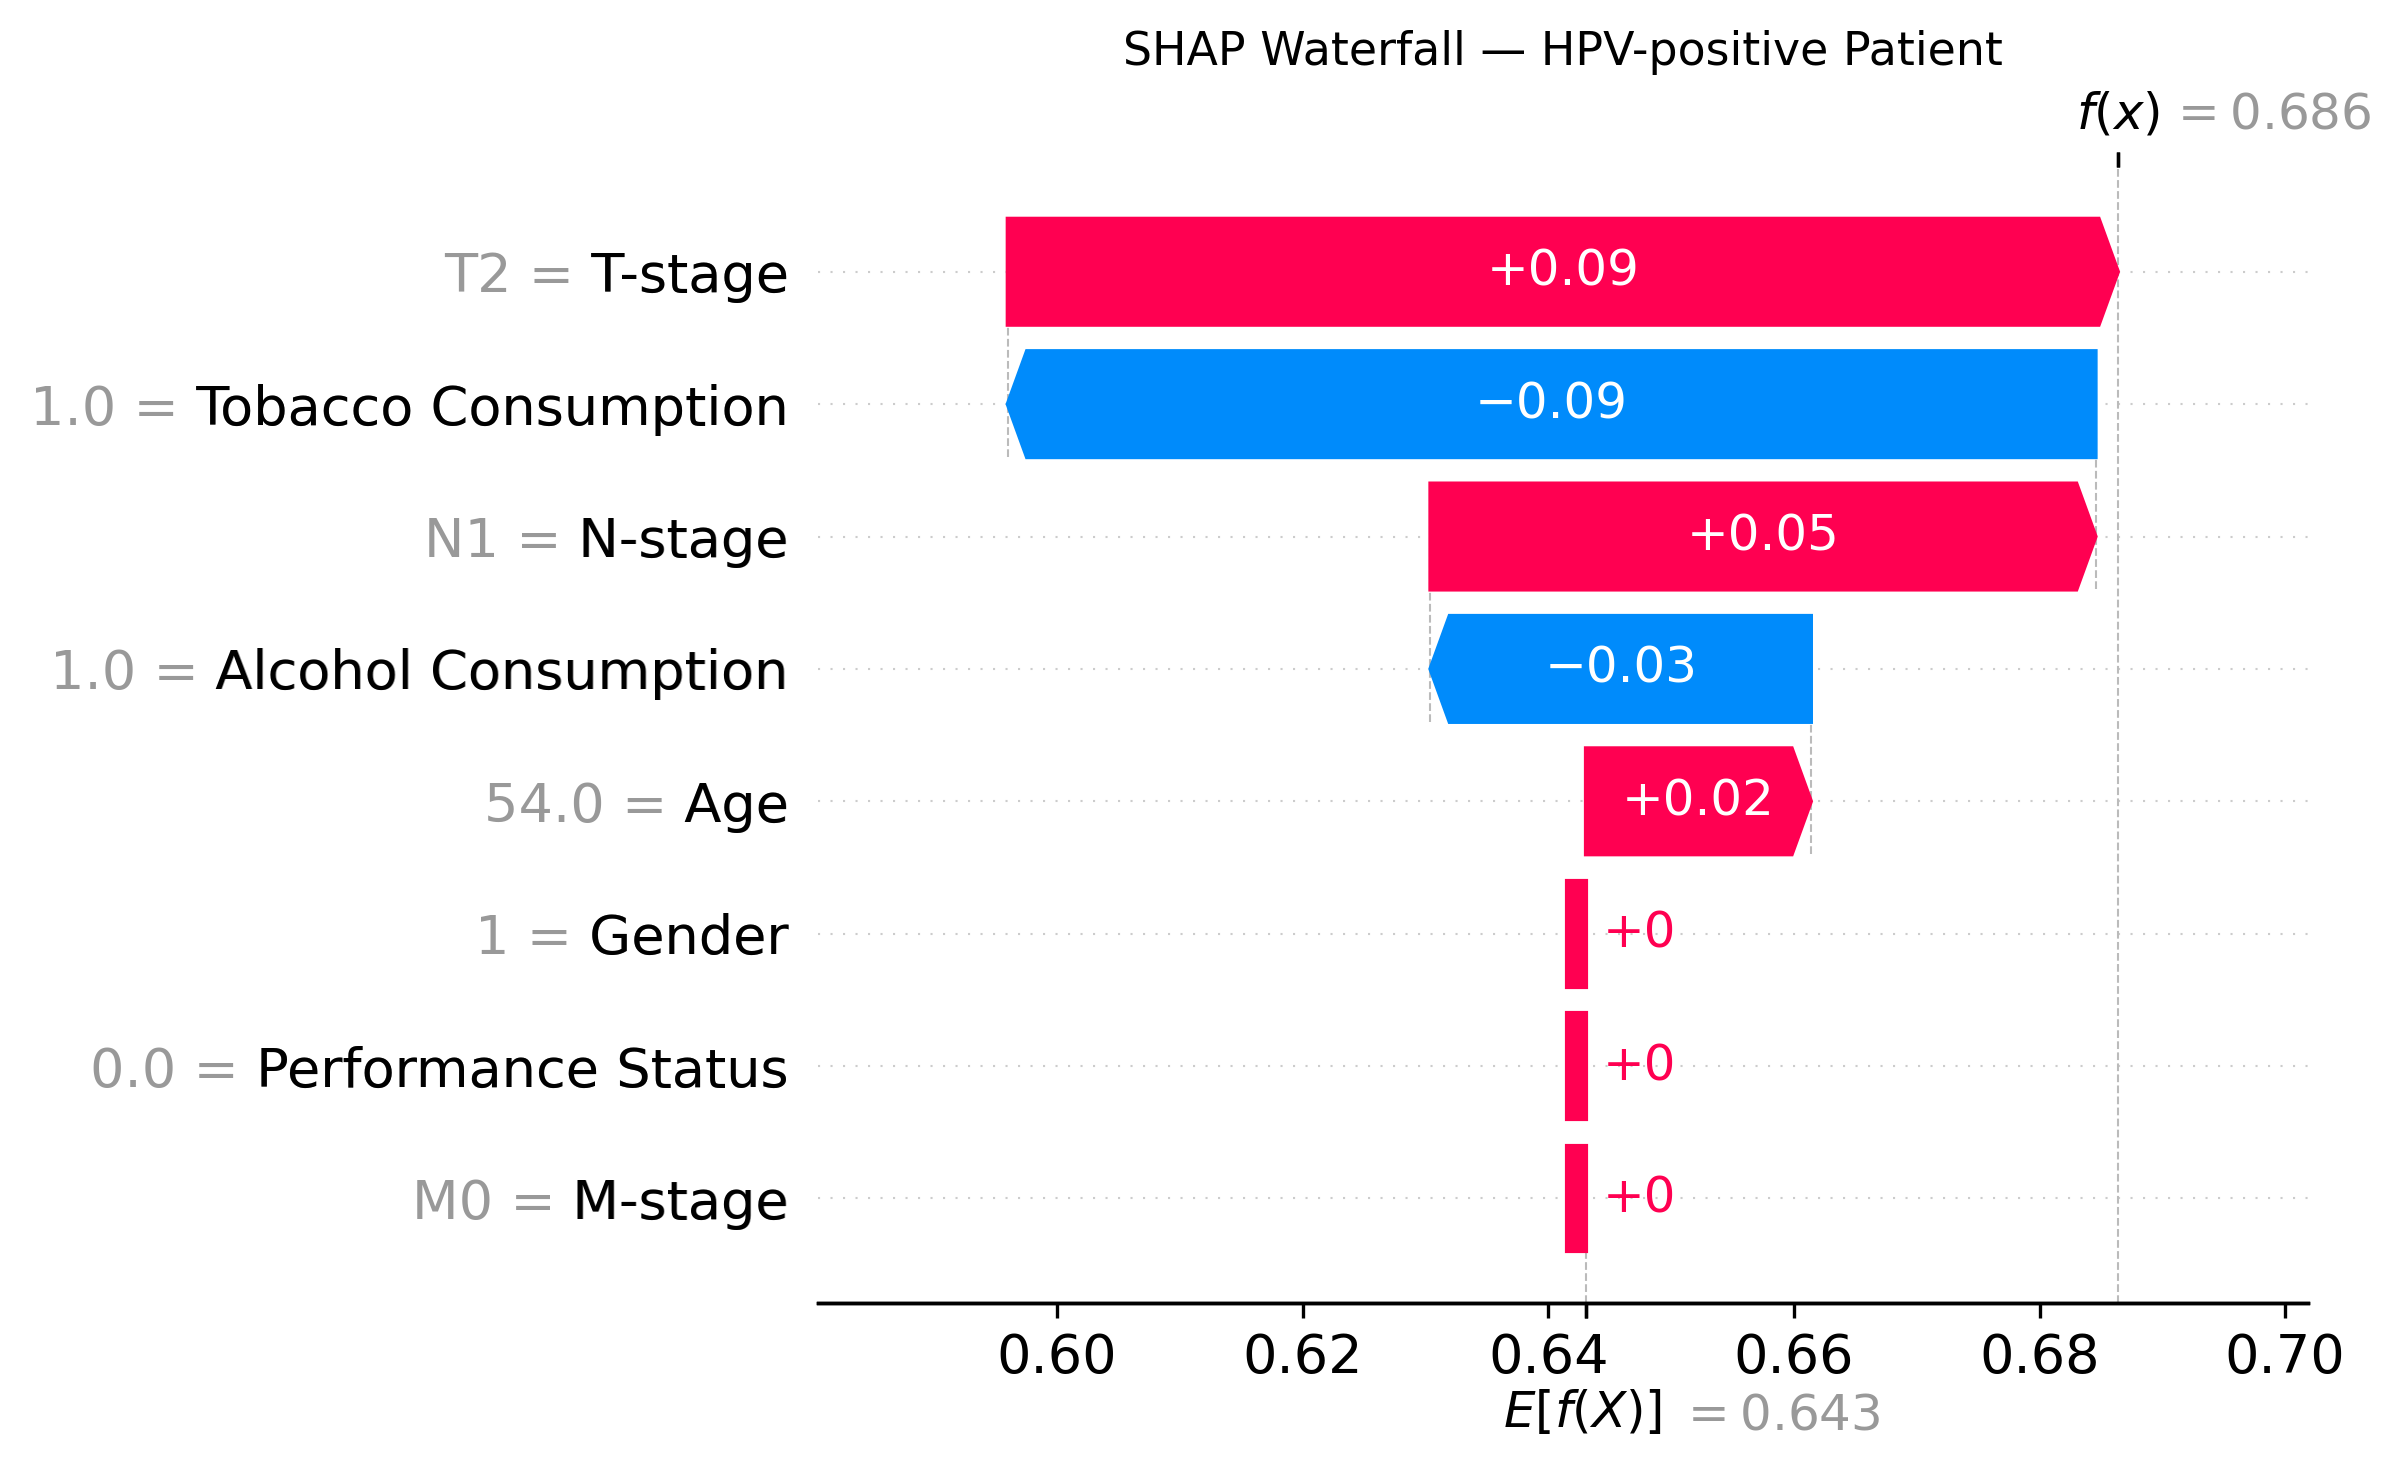

Saved: /content/CNN_results_HECKTOR/SHAP_LIME_Individual_Plots/HPV_positive_SHAP_waterfall.png


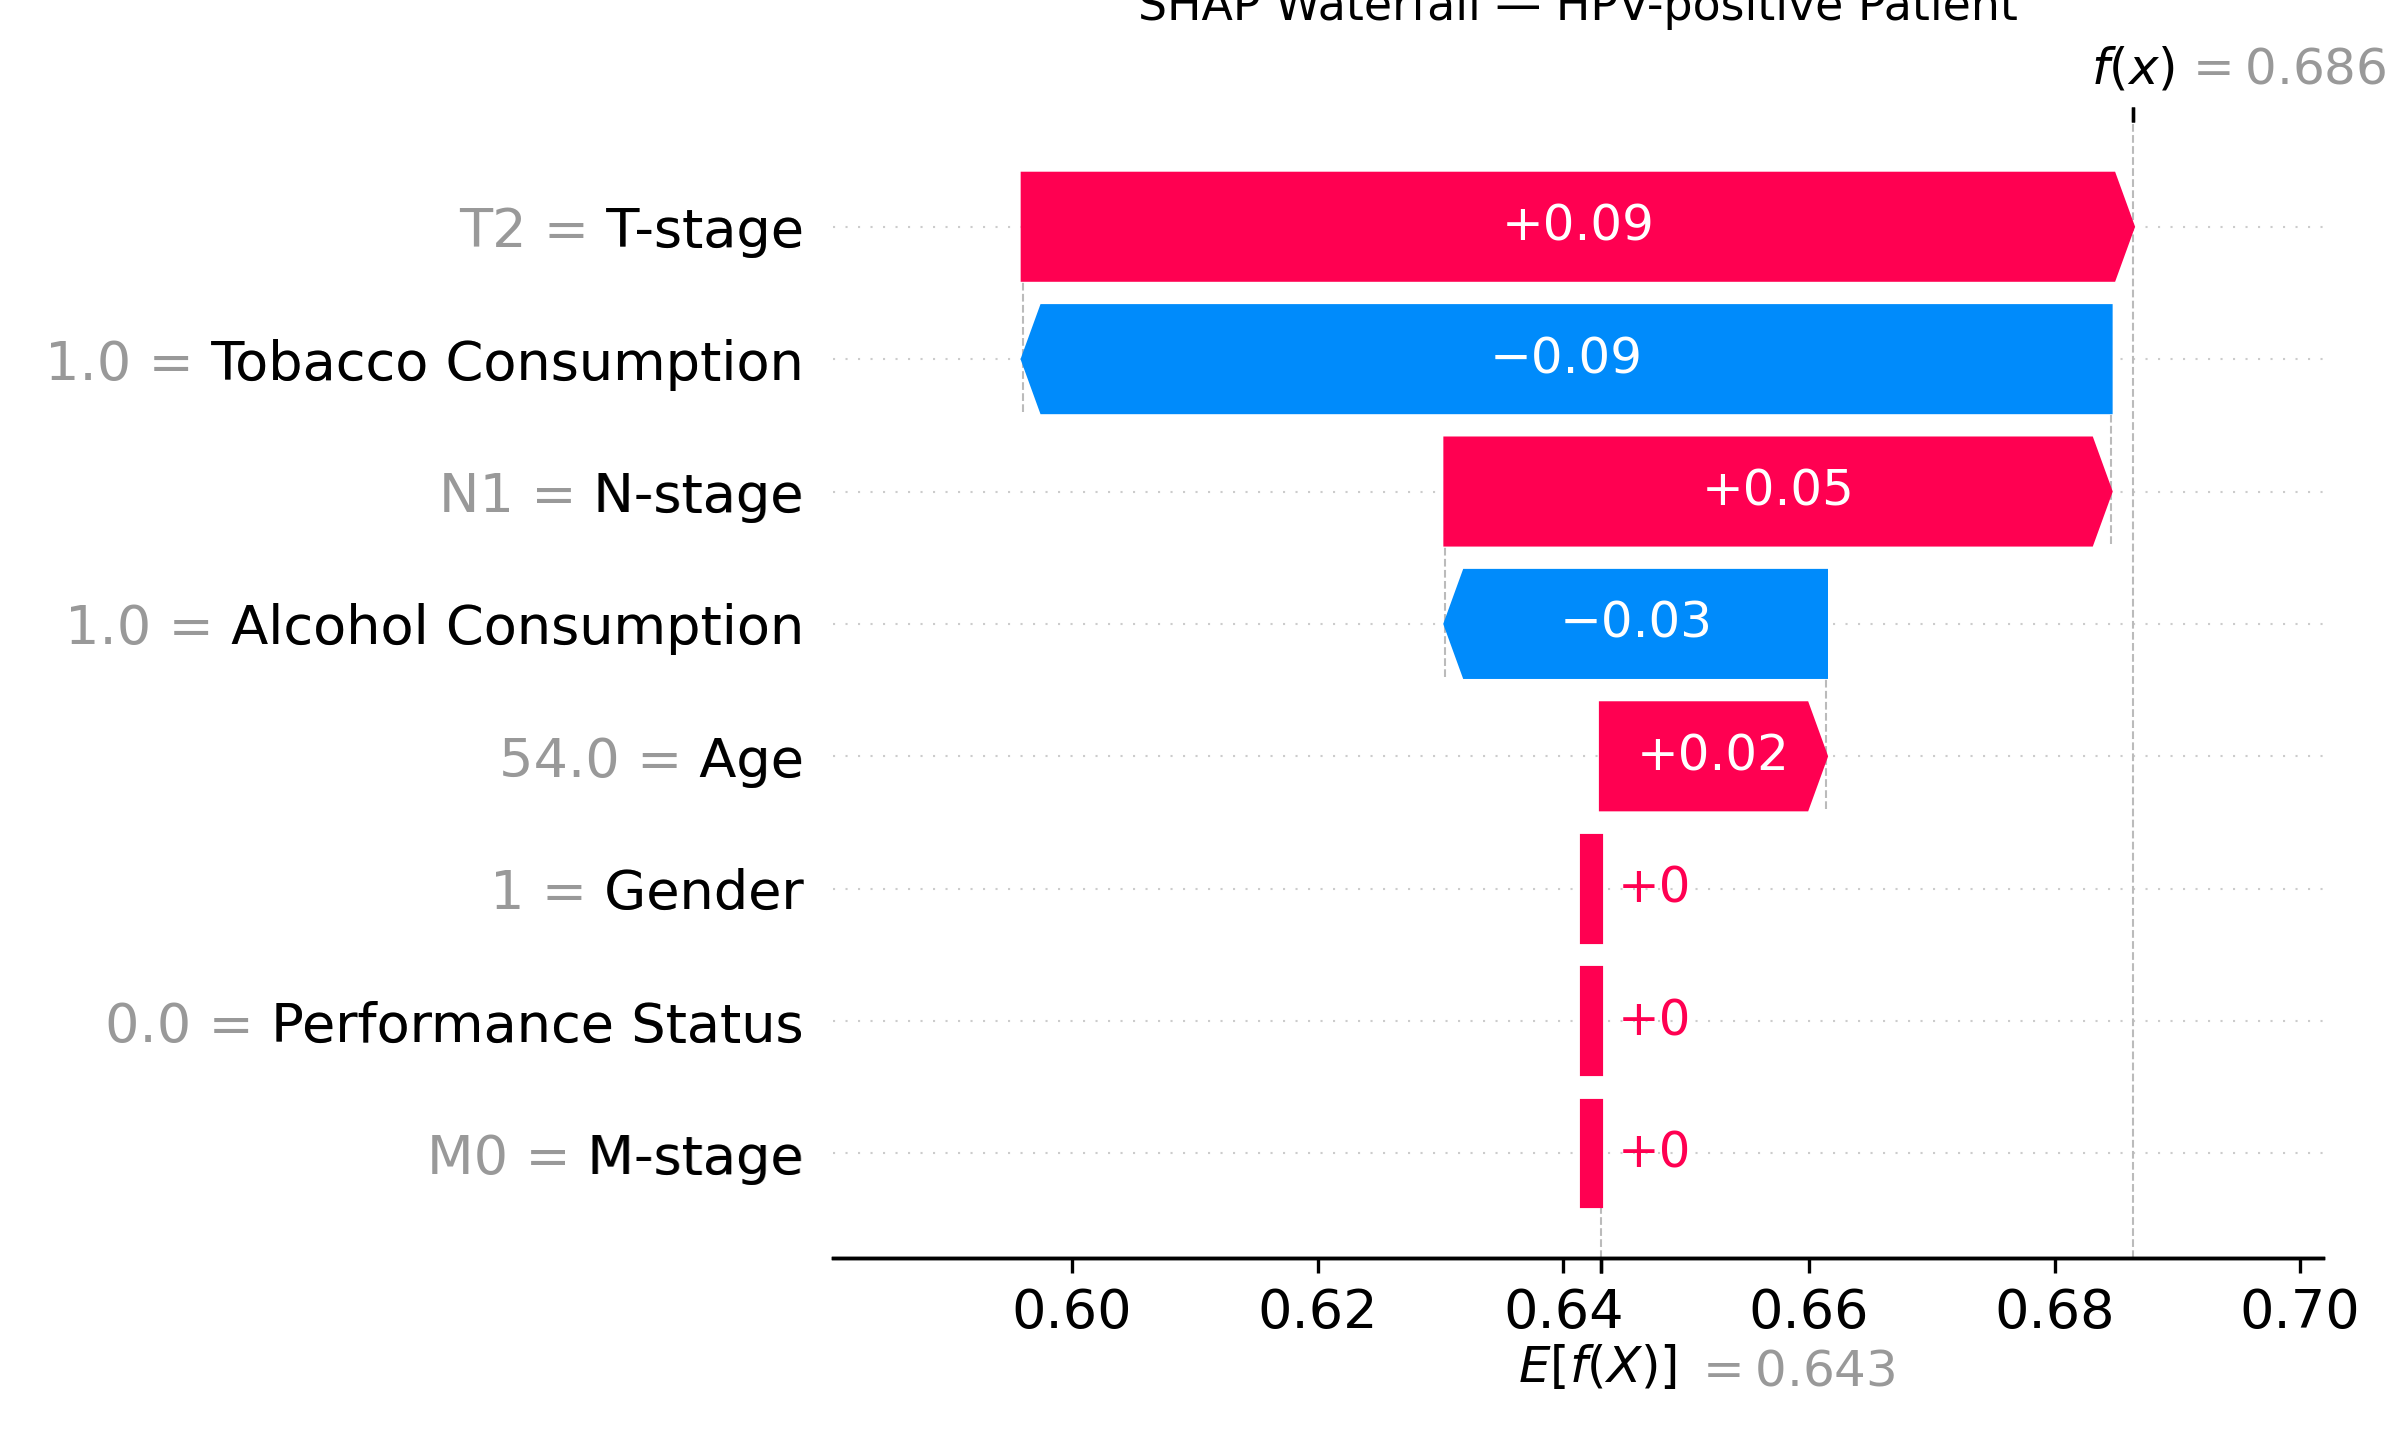

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

# ============================================================
# HPV-POSITIVE PATIENT — SHAP WATERFALL
# ============================================================

patient_label = "HPV_positive"
row = selected_patients[patient_label]

patient_encoded = X_test_np[row:row + 1]

raw_values = [
    test.iloc[row][feature] for feature in features
]

probability = float(
    cnn_predict_proba(patient_encoded)[0, 1]
)

shap_result = shap_explainer.shap_values(
    patient_encoded,
    nsamples=300
)

if isinstance(shap_result, list):
    shap_encoded = np.asarray(shap_result[0])
else:
    shap_encoded = np.asarray(shap_result)

if shap_encoded.ndim == 3:
    shap_encoded = shap_encoded[0, :, 0]
else:
    shap_encoded = shap_encoded.reshape(-1)

grouped_shap = np.array([
    shap_encoded[group_indices[feature]].sum()
    for feature in features
])

expected_value = float(
    np.asarray(shap_explainer.expected_value).reshape(-1)[0]
)

explanation = shap.Explanation(
    values=grouped_shap,
    base_values=expected_value,
    data=np.zeros(len(features)),
    display_data=[str(v) for v in raw_values],
    feature_names=display_names
)

plt.figure(figsize=(8, 4.8), dpi=300)

shap.plots.waterfall(
    explanation,
    max_display=8,
    show=False
)

fig = plt.gcf()
fig.set_size_inches(8, 4.8)
fig.tight_layout()

plt.title(
    "SHAP Waterfall — HPV-positive Patient",
    fontsize=11
)

filename = os.path.join(
    OUTPUT_DIR,
    "HPV_positive_SHAP_waterfall.png"
)

plt.savefig(filename, dpi=300, format="png")

plt.show()
plt.close()

print("Saved:", filename)
display(Image(filename=filename))

files.download(filename)


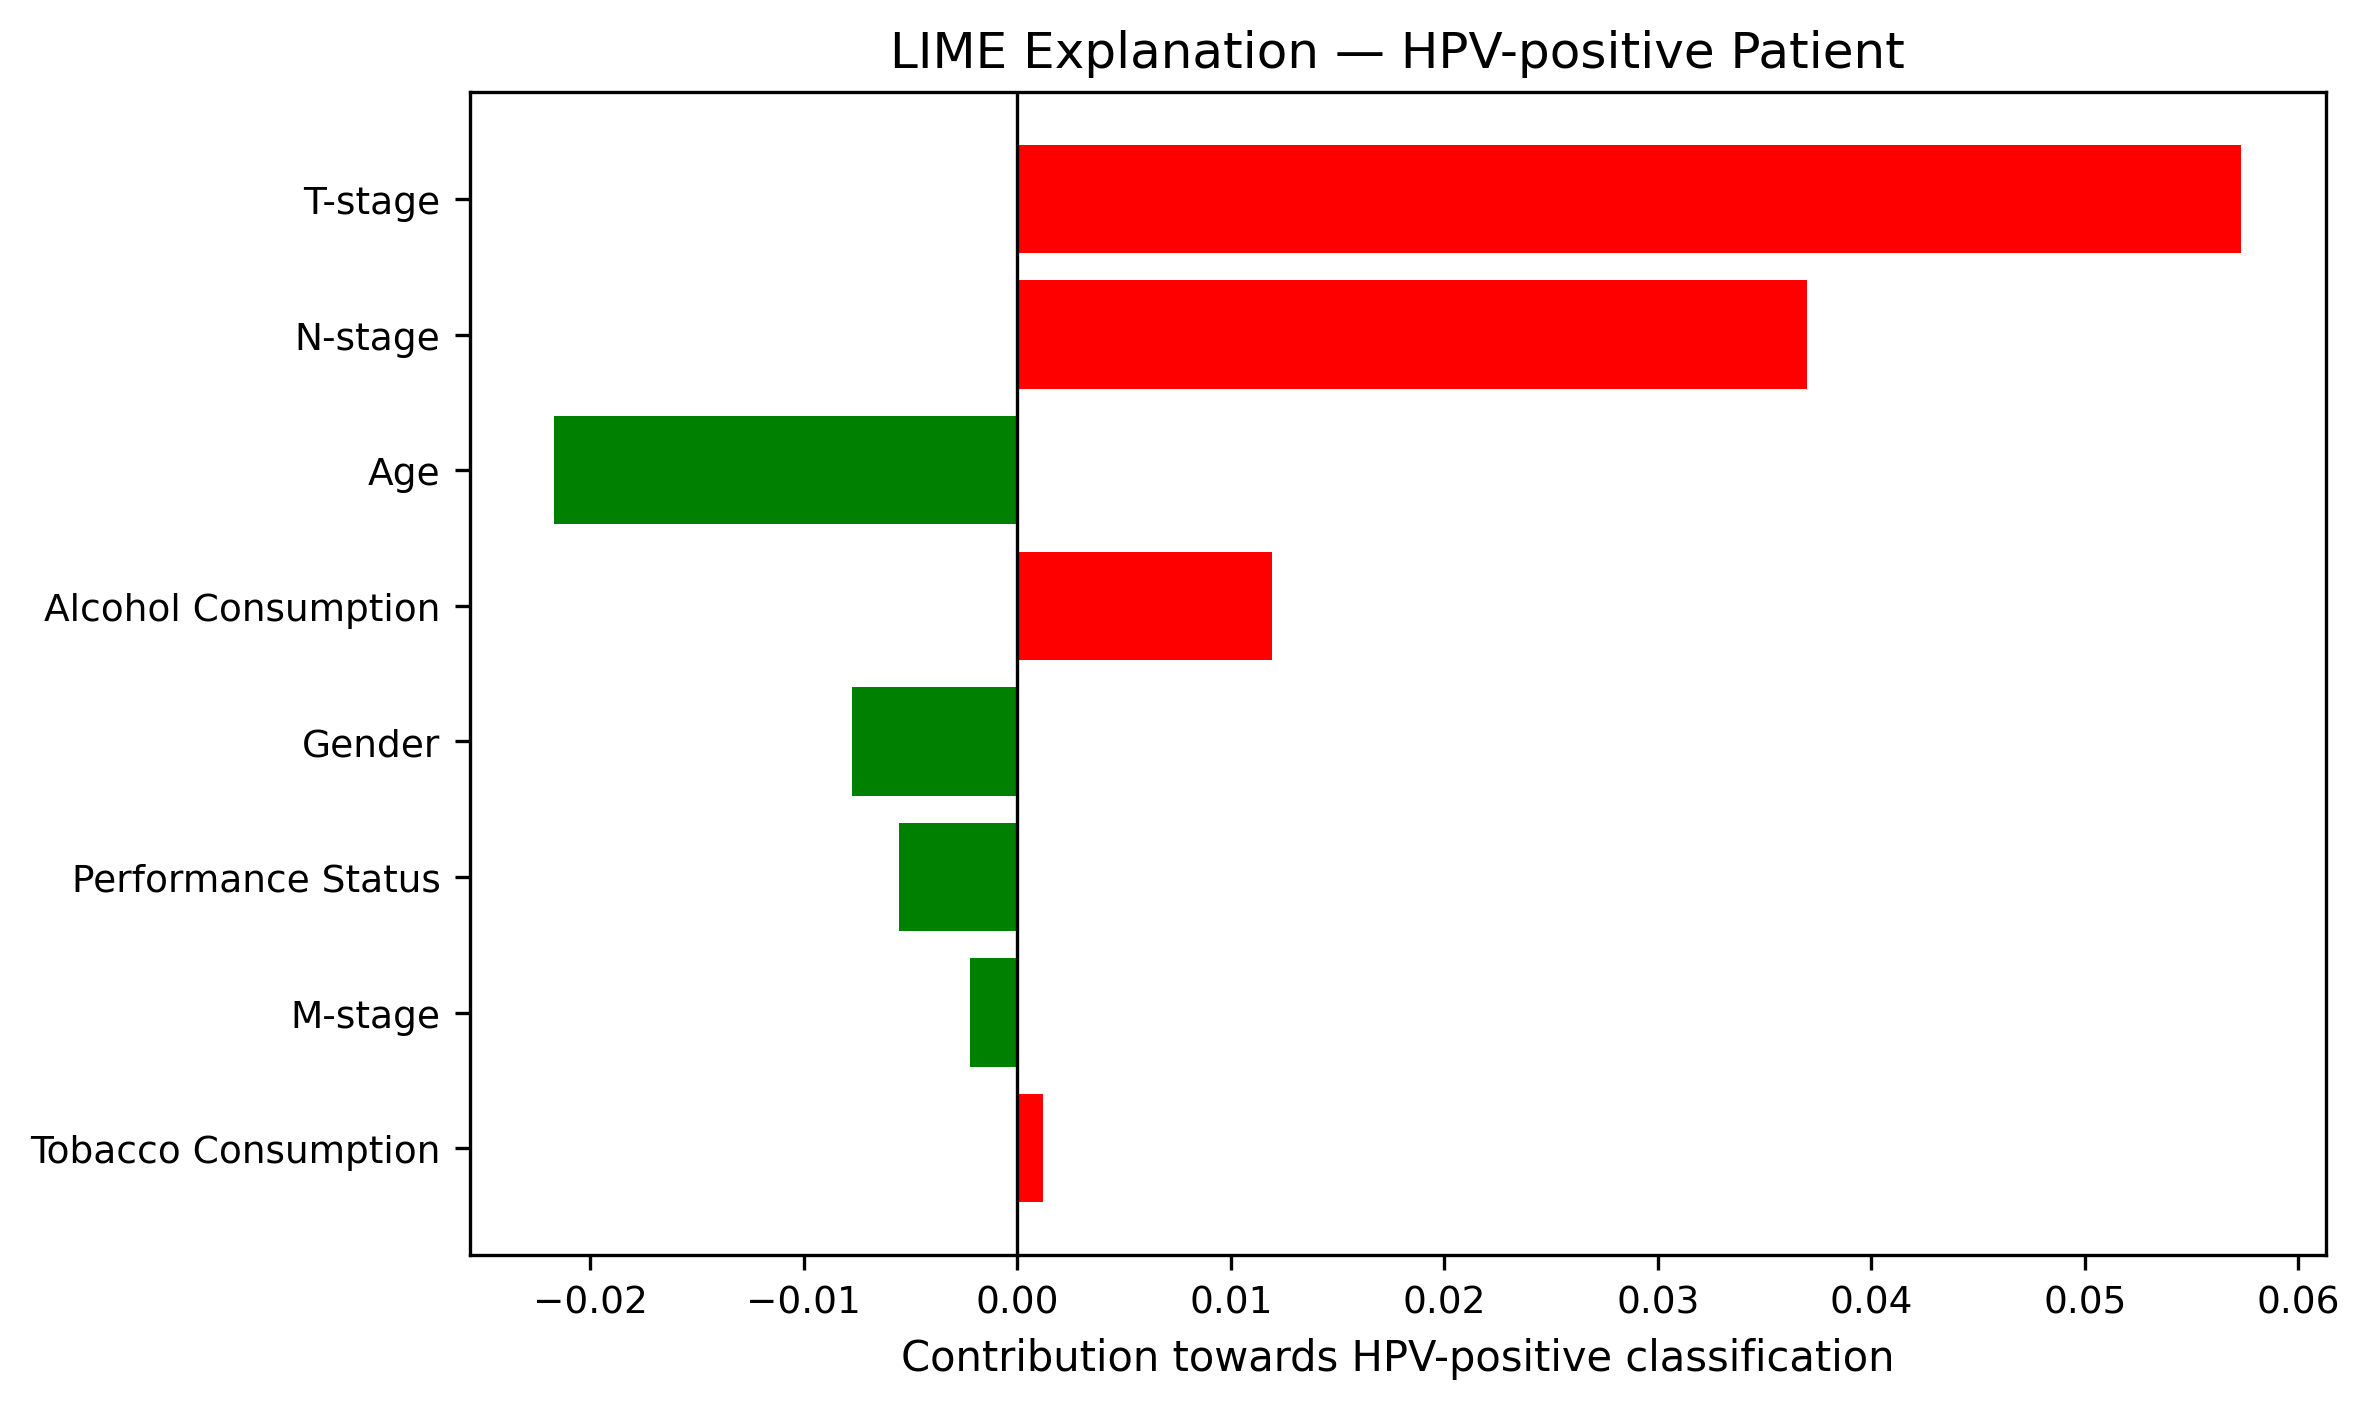

Saved: /content/CNN_results_HECKTOR/SHAP_LIME_Individual_Plots/HPV_positive_LIME_bar.png


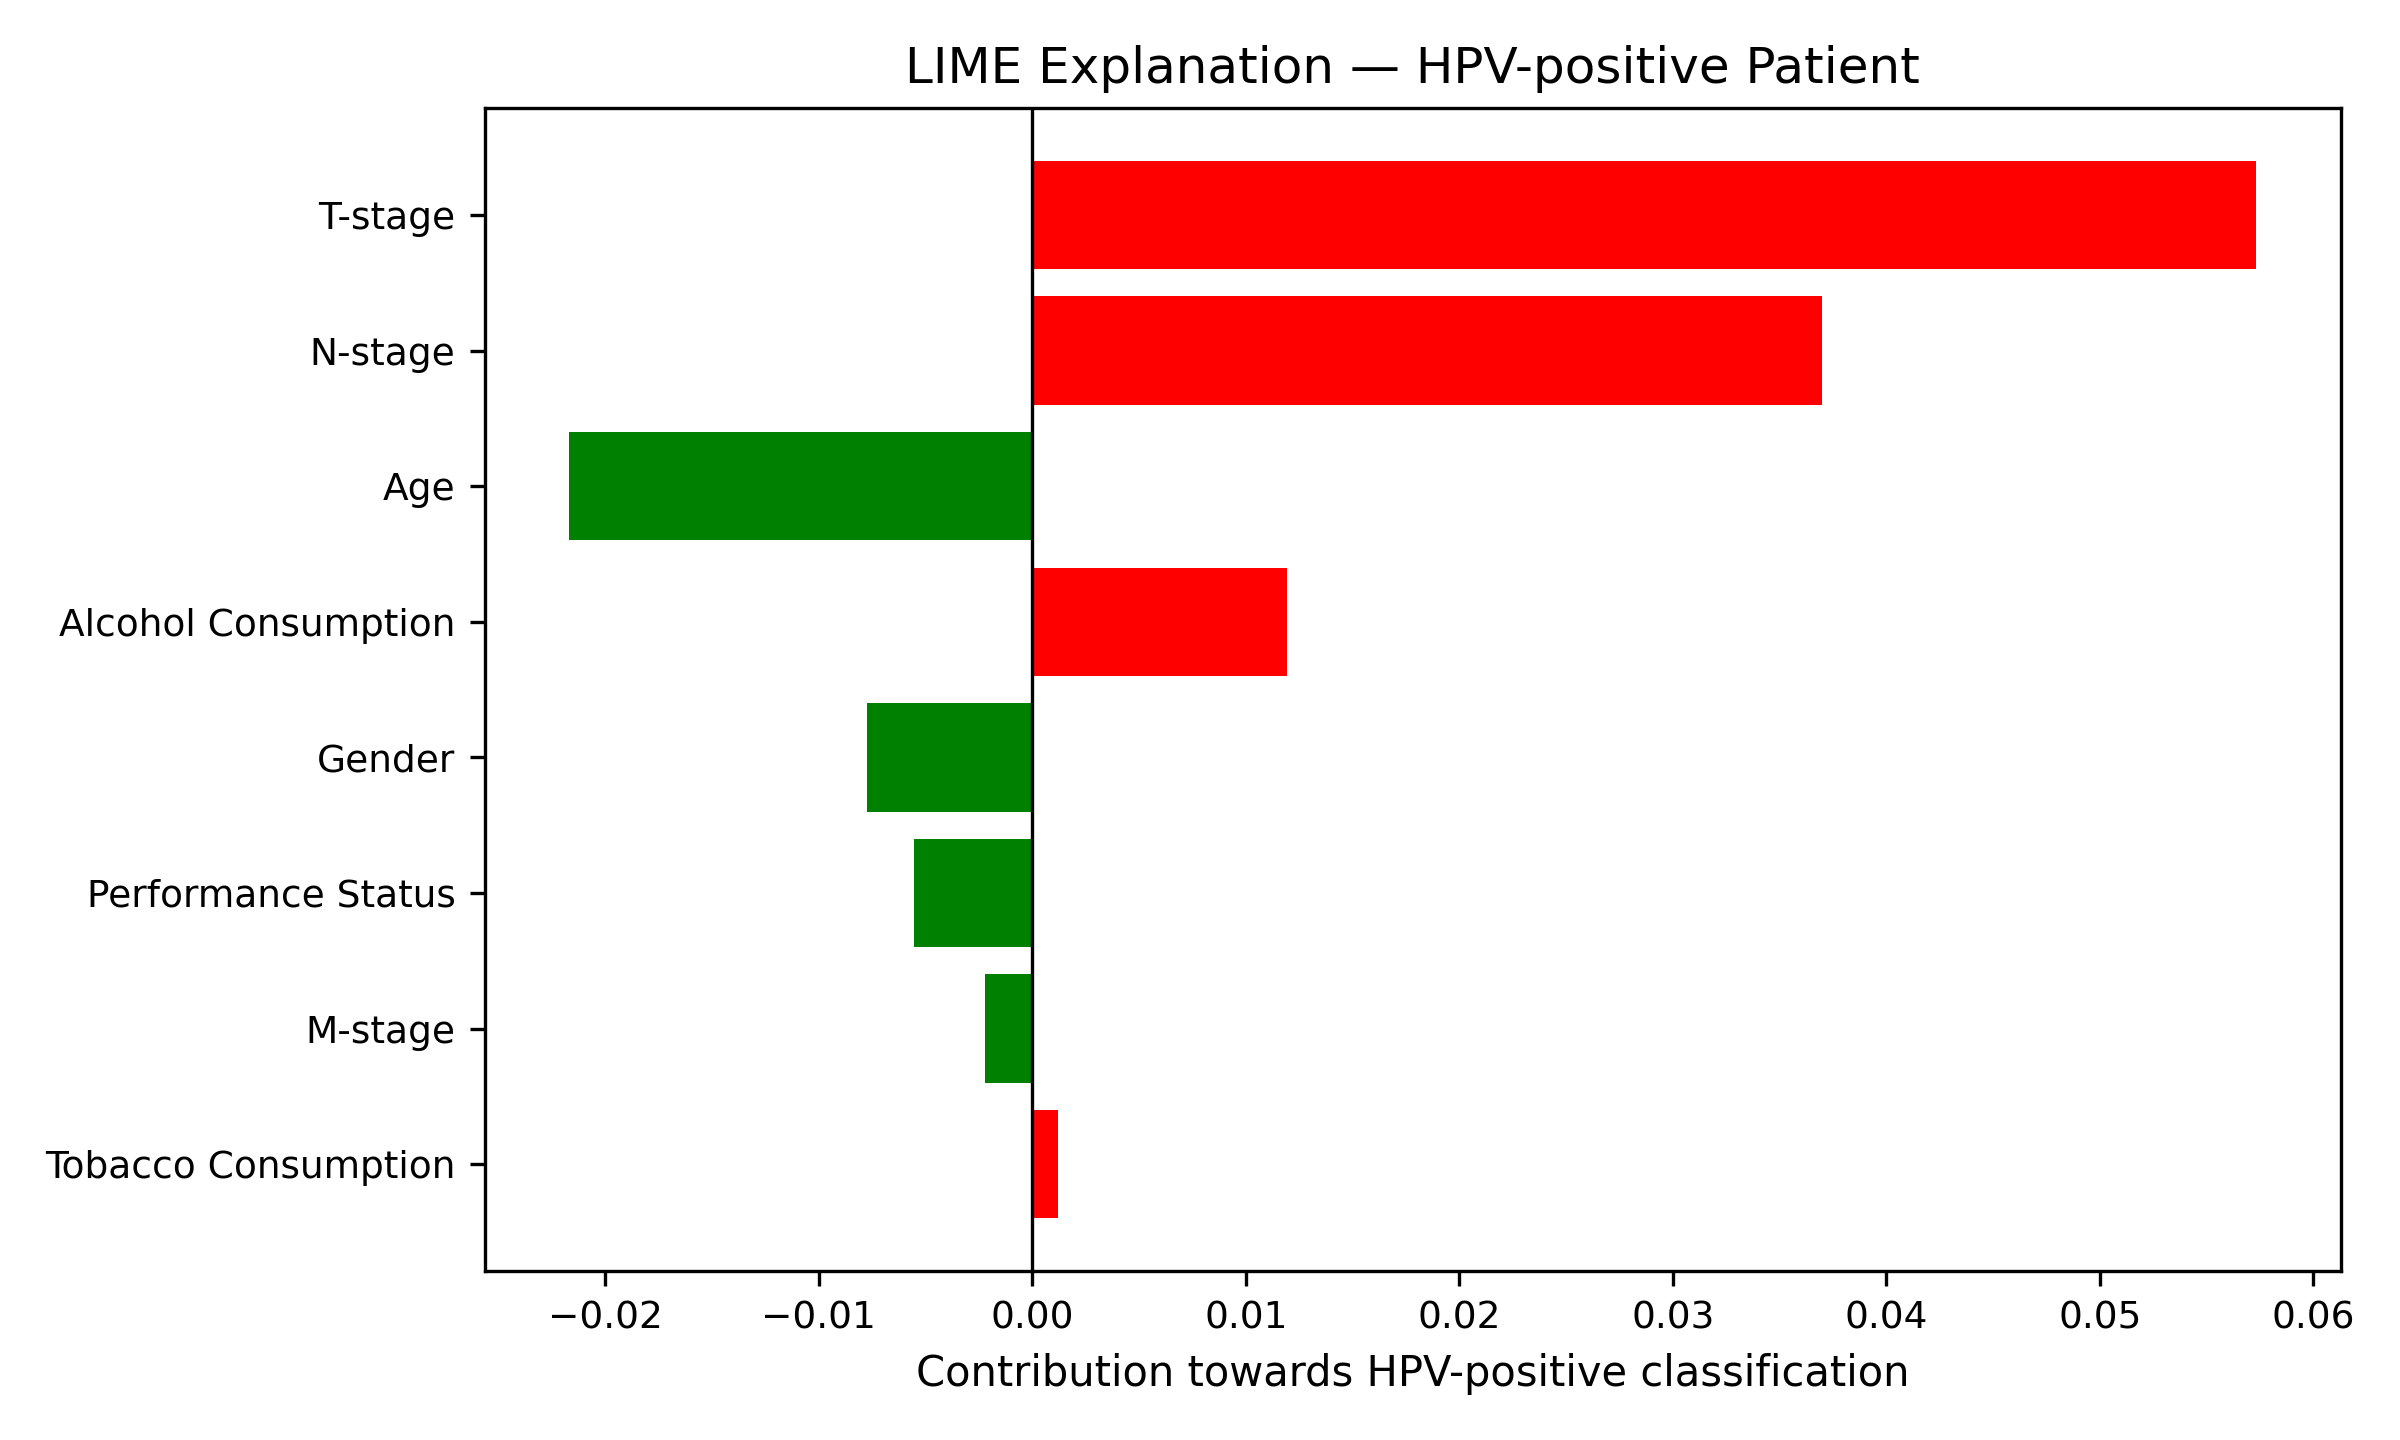

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:

# ============================================================
# HPV-POSITIVE PATIENT — LIME BAR CHART
# RED = TOWARDS HPV POSITIVE
# GREEN = AWAY FROM HPV POSITIVE
# ============================================================

patient_label = "HPV_positive"
row = selected_patients[patient_label]

patient_encoded = X_test_np[row:row + 1]

probability = float(
    cnn_predict_proba(patient_encoded)[0, 1]
)

lime_explanation = lime_explainer.explain_instance(
    data_row=patient_encoded[0],
    predict_fn=cnn_predict_proba,
    labels=(1,),
    num_features=len(encoded_feature_names),
    num_samples=3000
)

lime_weights = dict(lime_explanation.as_map()[1])

grouped_lime = np.array([
    sum(
        lime_weights.get(index, 0.0)
        for index in group_indices[feature]
    )
    for feature in features
])

order = np.argsort(np.abs(grouped_lime))

ordered_values = grouped_lime[order]
ordered_names = np.array(display_names)[order]

bar_colours = [
    "red" if value > 0 else "green"
    for value in ordered_values
]

fig, ax = plt.subplots(figsize=(8, 4.8), dpi=300)

ax.barh(
    ordered_names,
    ordered_values,
    color=bar_colours
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_xlabel(
    "Contribution towards HPV-positive classification"
)

ax.set_title(
    "LIME Explanation — HPV-positive Patient"
)

ax.tick_params(axis="both", labelsize=9)

fig.tight_layout()

filename = os.path.join(
    OUTPUT_DIR,
    "HPV_positive_LIME_bar.png"
)

fig.savefig(filename, dpi=300, format="png")

plt.show()
plt.close(fig)

print("Saved:", filename)
display(Image(filename=filename))

files.download(filename)


In [6]:
import os
import zipfile
from IPython.display import display, FileLink

OUTPUT_DIR = os.path.join(OUT_DIR, "SHAP_LIME_Individual_Plots")

plot_files = [
    "HPV_positive_SHAP_waterfall.png",
    "HPV_positive_LIME_bar.png",
    "HPV_negative_SHAP_waterfall.png",
    "HPV_negative_LIME_bar.png"
]

print("Checking plot files...")

for filename in plot_files:
    path = os.path.join(OUTPUT_DIR, filename)
    print(("FOUND: " if os.path.isfile(path) else "MISSING: ") + filename)

existing = [
    f for f in plot_files
    if os.path.isfile(os.path.join(OUTPUT_DIR, f))
]

if len(existing) == 4:
    zip_path = "/content/All_4_HPV_SHAP_LIME_Plots.zip"

    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for filename in plot_files:
            z.write(os.path.join(OUTPUT_DIR, filename), filename)

    print("\nZIP created successfully.")
    print("Click the link below to download:")
    display(FileLink(zip_path))
else:
    print("\nSome plots are missing. Please check the filenames above.")

Checking plot files...
FOUND: HPV_positive_SHAP_waterfall.png
FOUND: HPV_positive_LIME_bar.png
MISSING: HPV_negative_SHAP_waterfall.png
MISSING: HPV_negative_LIME_bar.png

Some plots are missing. Please check the filenames above.


In [8]:
# INITIALISE SHAP EXPLAINER

import numpy as np
import shap

# Convert training data to a NumPy array
X_train_array = np.asarray(X_train, dtype=np.float32)

# Select 25 background training samples
background = shap.sample(
    X_train_array,
    min(25, len(X_train_array))
)

# Create the SHAP explainer
explainer = shap.KernelExplainer(
    cnn_predict_proba,
    background
)

print("SHAP explainer successfully initialised.")

SHAP explainer successfully initialised.


In [14]:
# HPV-NEGATIVE SHAP WATERFALL - CORRECTED

negative_idx = np.where(
    np.asarray(y_test).reshape(-1) == 0
)[0][0]

x_negative = np.asarray(X_test[negative_idx], dtype=np.float32)
raw_negative = test.iloc[negative_idx][features]

# Calculate SHAP values
negative_shap_values = explainer.shap_values(
    x_negative.reshape(1, -1),
    nsamples=300
)

# Handle different SHAP output formats
if isinstance(negative_shap_values, list):
    negative_shap_values = negative_shap_values[-1]

negative_shap_values = np.asarray(negative_shap_values)

if negative_shap_values.ndim == 3:
    negative_shap_values = negative_shap_values[0, :, -1]
elif negative_shap_values.ndim == 2:
    negative_shap_values = negative_shap_values[0]

negative_shap_values = negative_shap_values.flatten()

# Group encoded SHAP values by original clinical feature
grouped_values = []

for feature in features:
    indices = [
        int(idx)
        for idx, original_feature in encoded_to_original.items()
        if original_feature == feature
    ]

    grouped_values.append(
        negative_shap_values[indices].sum() if indices else 0.0
    )

grouped_values = np.asarray(grouped_values)

# Create SHAP explanation
negative_explanation = shap.Explanation(
    values=grouped_values,
    base_values=float(
        np.asarray(explainer.expected_value).reshape(-1)[-1]
    ),
    data=np.zeros(len(features)),
    feature_names=features,
    display_data=raw_negative.values
)

# Plot with consistent dimensions
fig, ax = plt.subplots(figsize=(8, 4.8), dpi=300)
plt.close(fig)

shap.plots.waterfall(
    negative_explanation,
    show=False,
    max_display=8
)

fig = plt.gcf()
fig.set_size_inches(8, 4.8)
fig.set_dpi(300)
fig.tight_layout()

negative_shap_path = os.path.join(
    OUTPUT_DIR,
    "HPV_negative_SHAP_waterfall.png"
)

fig.savefig(negative_shap_path, dpi=300)
plt.show()
plt.close(fig)

print("HPV-negative SHAP plot saved successfully:", negative_shap_path)

  0%|          | 0/1 [00:00<?, ?it/s]

NameError: name 'encoded_to_original' is not defined

In [16]:
# CREATE THE MISSING ENCODED-TO-ORIGINAL FEATURE MAPPING

encoded_feature_names = list(preprocessor.get_feature_names_out())

encoded_to_original = {}

for idx, encoded_name in enumerate(encoded_feature_names):
    clean_name = encoded_name.split("__")[-1]

    matches = [
        feature for feature in features
        if clean_name == feature
        or clean_name.startswith(feature + "_")
    ]

    if matches:
        encoded_to_original[idx] = max(matches, key=len)

print("Total encoded columns:", len(encoded_feature_names))
print("Successfully mapped:", len(encoded_to_original))

for idx, name in encoded_to_original.items():
    print(f"{idx}: {encoded_feature_names[idx]} -> {name}")

unmapped = [
    name for idx, name in enumerate(encoded_feature_names)
    if idx not in encoded_to_original
]

print("\nUnmapped columns:", unmapped)

Total encoded columns: 23
Successfully mapped: 23
0: numeric__Age -> Age
1: categorical__Gender_0 -> Gender
2: categorical__Gender_1 -> Gender
3: categorical__Tobacco Consumption_0.0 -> Tobacco Consumption
4: categorical__Tobacco Consumption_1.0 -> Tobacco Consumption
5: categorical__Alcohol Consumption_0.0 -> Alcohol Consumption
6: categorical__Alcohol Consumption_1.0 -> Alcohol Consumption
7: categorical__Performance Status_0.0 -> Performance Status
8: categorical__Performance Status_1.0 -> Performance Status
9: categorical__Performance Status_2.0 -> Performance Status
10: categorical__Performance Status_3.0 -> Performance Status
11: categorical__Performance Status_4.0 -> Performance Status
12: categorical__T-stage_T0 -> T-stage
13: categorical__T-stage_T1 -> T-stage
14: categorical__T-stage_T2 -> T-stage
15: categorical__T-stage_T3 -> T-stage
16: categorical__T-stage_T4 -> T-stage
17: categorical__N-stage_N0 -> N-stage
18: categorical__N-stage_N1 -> N-stage
19: categorical__N-stage_

In [23]:
def cnn_predict_proba(data):
    data = np.asarray(data, dtype=np.float32)
    model.eval()
    predictions = []

    with torch.no_grad():
        for start in range(0, len(data), 512):
            batch = data[start:start + 512]
            tensor = torch.tensor(batch, dtype=torch.float32, device=device)
            logits = model(tensor)
            probabilities = torch.softmax(logits, dim=1)
            predictions.append(probabilities.cpu().numpy())

    return np.vstack(predictions)

In [24]:
test_predictions = cnn_predict_proba(X_test_array[:5])
print(test_predictions.shape)
print(test_predictions)

(5, 2)
[[0.31362414 0.68637586]
 [0.54878247 0.45121747]
 [0.48816833 0.5118317 ]
 [0.588982   0.411018  ]
 [0.37629285 0.6237072 ]]


In [25]:
# ================================================================
# CNN HPV CLASSIFICATION: SHAP + LIME EXPLANATIONS
# Generates 4 individual plots and a downloadable ZIP file
# ================================================================

# 1. INSTALL REQUIRED LIBRARIES
!pip -q install shap lime

import os
import numpy as np
import pandas as pd
import torch
import shap
import matplotlib.pyplot as plt
import zipfile

from lime.lime_tabular import LimeTabularExplainer
from matplotlib.patches import Patch
from IPython.display import display, FileLink

# ================================================================
# 2. CHECK REQUIRED VARIABLES
# ================================================================

required_variables = [
    "model", "device", "X_train", "X_test",
    "y_test", "preprocessor", "features", "OUT_DIR"
]

for variable in required_variables:
    if variable not in globals():
        raise NameError(
            f"Missing variable: {variable}. "
            "Please run the CNN training notebook cells first."
        )

# ================================================================
# 3. LOAD BEST CNN CHECKPOINT
# ================================================================

checkpoint_path = os.path.join(
    OUT_DIR,
    "checkpoints",
    "cnn_best_val_roc_auc.pt"
)

if os.path.exists(checkpoint_path):

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )
    except TypeError:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device
        )

    if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        model.load_state_dict(checkpoint["model_state_dict"])
    else:
        model.load_state_dict(checkpoint)

    print("Best CNN checkpoint loaded successfully.")

else:
    raise FileNotFoundError(
        f"Checkpoint not found: {checkpoint_path}"
    )

model.eval()

# ================================================================
# 4. PREPARE DATA
# ================================================================

X_train_array = np.asarray(
    X_train,
    dtype=np.float32
)

X_test_array = np.asarray(
    X_test,
    dtype=np.float32
)

y_test_array = np.asarray(y_test).astype(int).ravel()

encoded_feature_names = list(
    preprocessor.get_feature_names_out()
)

n_features = X_train_array.shape[1]

print("Training data shape:", X_train_array.shape)
print("Test data shape:", X_test_array.shape)
print("Number of encoded features:", n_features)

if X_test_array.shape[1] != n_features:
    raise ValueError("Training and test feature dimensions do not match.")

if len(y_test_array) != len(X_test_array):
    raise ValueError("Test labels and test data lengths do not match.")

# ================================================================
# 5. CORRECT CNN PREDICTION FUNCTION
# IMPORTANT: DO NOT ADD UNSQUEEZE(1)
# ================================================================

def cnn_predict_proba(data):

    data = np.asarray(data, dtype=np.float32)

    if data.ndim != 2:
        raise ValueError(
            f"Expected 2D input, received {data.shape}"
        )

    if data.shape[1] != n_features:
        raise ValueError(
            f"Expected {n_features} features, "
            f"received {data.shape[1]}"
        )

    model.eval()
    predictions = []

    with torch.no_grad():

        for start in range(0, len(data), 512):

            batch = data[start:start + 512]

            tensor = torch.tensor(
                batch,
                dtype=torch.float32,
                device=device
            )

            # Model adds its own channel dimension internally
            logits = model(tensor)

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            predictions.append(
                probabilities.cpu().numpy()
            )

    return np.vstack(predictions)


# Test prediction function
test_prediction = cnn_predict_proba(X_test_array[:5])

print("\nPrediction test shape:", test_prediction.shape)
print("Prediction test successful.")

# ================================================================
# 6. MAP ENCODED FEATURES TO ORIGINAL 8 FEATURES
# ================================================================

encoded_to_original = {}

for idx, encoded_name in enumerate(encoded_feature_names):

    clean_name = encoded_name.split("__")[-1]

    matches = [
        feature for feature in features
        if (
            clean_name == feature
            or clean_name.startswith(feature + "_")
        )
    ]

    if matches:
        encoded_to_original[idx] = max(matches, key=len)

unmapped = [
    name for idx, name in enumerate(encoded_feature_names)
    if idx not in encoded_to_original
]

if unmapped:
    raise ValueError(
        f"Some encoded features could not be mapped: {unmapped}"
    )

print("\nOriginal feature mapping:")
for idx, name in enumerate(encoded_feature_names):
    print(f"{name} -> {encoded_to_original[idx]}")

# ================================================================
# 7. SELECT ONE ACTUAL HPV-POSITIVE AND ONE NEGATIVE PATIENT
# ================================================================

positive_indices = np.where(y_test_array == 1)[0]
negative_indices = np.where(y_test_array == 0)[0]

if len(positive_indices) == 0:
    raise ValueError("No actual HPV-positive patient found in test set.")

if len(negative_indices) == 0:
    raise ValueError("No actual HPV-negative patient found in test set.")

positive_idx = int(positive_indices[0])
negative_idx = int(negative_indices[0])

selected_patients = [
    ("HPV_positive", positive_idx, 1),
    ("HPV_negative", negative_idx, 0)
]

print("\nSelected patients:")
print("HPV-positive test index:", positive_idx)
print("HPV-negative test index:", negative_idx)

# ================================================================
# 8. GET ORIGINAL FEATURE VALUES FOR EACH PATIENT
# ================================================================

def get_original_values(test_index):

    if "test" in globals():

        if isinstance(test, pd.DataFrame):
            return test.iloc[test_index][features].values

    raise ValueError(
        "Original test DataFrame 'test' is unavailable. "
        "Please ensure the original test DataFrame is retained."
    )


# ================================================================
# 9. CREATE OUTPUT FOLDER
# ================================================================

OUTPUT_DIR = os.path.join(
    OUT_DIR,
    "SHAP_LIME_Individual_Plots"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\nOutput folder:", OUTPUT_DIR)

# ================================================================
# 10. PREPARE SHAP BACKGROUND DATA
# ================================================================

np.random.seed(42)

background_size = min(25, len(X_train_array))

background_indices = np.random.choice(
    len(X_train_array),
    size=background_size,
    replace=False
)

background = X_train_array[background_indices]

# ================================================================
# 11. INITIALISE LIME EXPLAINER
# ================================================================

lime_explainer = LimeTabularExplainer(
    training_data=X_train_array,
    feature_names=encoded_feature_names,
    class_names=["HPV-negative", "HPV-positive"],
    mode="classification",
    discretize_continuous=False,
    random_state=42
)

# ================================================================
# 12. HELPER: GROUP ENCODED VALUES INTO ORIGINAL FEATURES
# ================================================================

def group_encoded_values(encoded_values):

    grouped = {
        feature: 0.0 for feature in features
    }

    for encoded_idx, value in enumerate(encoded_values):

        original_feature = encoded_to_original[encoded_idx]

        grouped[original_feature] += float(value)

    return np.array([
        grouped[feature] for feature in features
    ])


# ================================================================
# 13. GENERATE SHAP AND LIME PLOTS
# ================================================================

for patient_name, patient_idx, class_label in selected_patients:

    print("\n" + "=" * 65)
    print("GENERATING EXPLANATIONS FOR:", patient_name)
    print("=" * 65)

    patient = X_test_array[patient_idx]

    original_values = get_original_values(patient_idx)

    # ------------------------------------------------------------
    # A. SHAP EXPLANATION
    # ------------------------------------------------------------

    print("Calculating SHAP values...")

    def predict_selected_class(data):
        return cnn_predict_proba(data)[:, class_label]

    shap_explainer = shap.KernelExplainer(
        predict_selected_class,
        background
    )

    shap_values = shap_explainer.shap_values(
        patient.reshape(1, -1),
        nsamples=300
    )

    if isinstance(shap_values, list):
        shap_values = shap_values[0]

    shap_values = np.asarray(shap_values).reshape(-1)

    grouped_shap_values = group_encoded_values(shap_values)

    base_value = float(
        np.asarray(shap_explainer.expected_value).reshape(-1)[0]
    )

    # Create SHAP waterfall plot
    shap_explanation = shap.Explanation(
        values=grouped_shap_values,
        base_values=base_value,
        data=original_values,
        feature_names=features
    )

    plt.figure(figsize=(8, 4.8))

    shap.plots.waterfall(
        shap_explanation,
        max_display=len(features),
        show=False
    )

    fig = plt.gcf()
    fig.set_size_inches(8, 4.8)

    plt.title(
        f"SHAP Explanation - {patient_name}",
        fontsize=12
    )

    plt.tight_layout()

    shap_filename = os.path.join(
        OUTPUT_DIR,
        f"{patient_name}_SHAP_waterfall.png"
    )

    plt.savefig(
        shap_filename,
        dpi=300,
        facecolor="white"
    )

    plt.close("all")

    print("Saved SHAP:", shap_filename)

    # ------------------------------------------------------------
    # B. LIME EXPLANATION
    # ------------------------------------------------------------

    print("Calculating LIME values...")

    lime_explanation = lime_explainer.explain_instance(
        data_row=patient,
        predict_fn=cnn_predict_proba,
        labels=(class_label,),
        num_features=n_features,
        num_samples=2000
    )

    lime_map = lime_explanation.as_map()[class_label]

    grouped_lime_values = {
        feature: 0.0 for feature in features
    }

    for encoded_idx, weight in lime_map:

        original_feature = encoded_to_original[encoded_idx]

        grouped_lime_values[original_feature] += float(weight)

    lime_values = np.array([
        grouped_lime_values[feature]
        for feature in features
    ])

    # ------------------------------------------------------------
    # C. PLOT LIME BAR CHART
    # ------------------------------------------------------------

    order = np.argsort(np.abs(lime_values))

    ordered_features = np.array(features)[order]
    ordered_values = lime_values[order]

    # Red = contribution toward the selected class
    # Green = contribution away from the selected class
    colors = [
        "red" if value >= 0 else "green"
        for value in ordered_values
    ]

    fig, ax = plt.subplots(figsize=(8, 4.8))

    ax.barh(
        ordered_features,
        ordered_values,
        color=colors,
        edgecolor="black",
        linewidth=0.4
    )

    ax.axvline(
        x=0,
        color="black",
        linewidth=0.8
    )

    ax.set_xlabel(
        "LIME contribution toward selected class",
        fontsize=10
    )

    ax.set_ylabel(
        "Original clinical features",
        fontsize=10
    )

    ax.set_title(
        f"LIME Explanation - {patient_name}",
        fontsize=12
    )

    ax.legend(
        handles=[
            Patch(color="red", label="Positive contribution"),
            Patch(color="green", label="Negative contribution")
        ],
        loc="best",
        fontsize=8
    )

    ax.tick_params(axis="both", labelsize=9)

    plt.tight_layout()

    lime_filename = os.path.join(
        OUTPUT_DIR,
        f"{patient_name}_LIME_bar.png"
    )

    plt.savefig(
        lime_filename,
        dpi=300,
        facecolor="white"
    )

    plt.close("all")

    print("Saved LIME:", lime_filename)

# ================================================================
# 14. CHECK ALL FOUR PLOTS
# ================================================================

expected_files = [
    "HPV_positive_SHAP_waterfall.png",
    "HPV_positive_LIME_bar.png",
    "HPV_negative_SHAP_waterfall.png",
    "HPV_negative_LIME_bar.png"
]

print("\n" + "=" * 65)
print("CHECKING GENERATED PLOTS")
print("=" * 65)

for filename in expected_files:

    filepath = os.path.join(OUTPUT_DIR, filename)

    if os.path.exists(filepath):

        image = plt.imread(filepath)

        print(
            "FOUND:",
            filename,
            "| Image dimensions:",
            image.shape
        )

    else:
        print("MISSING:", filename)

# ================================================================
# 15. CREATE ZIP FILE
# ================================================================

zip_path = os.path.join(
    OUTPUT_DIR,
    "ALL_4_HPV_SHAP_LIME_PLOTS.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in expected_files:

        filepath = os.path.join(OUTPUT_DIR, filename)

        if os.path.exists(filepath):
            zip_file.write(
                filepath,
                arcname=filename
            )

print("\nZIP file created:", zip_path)

# ================================================================
# 16. DISPLAY DOWNLOAD LINKS
# ================================================================

print("\n" + "=" * 65)
print("DOWNLOAD YOUR FOUR SHAP AND LIME PLOTS")
print("=" * 65)

for filename in expected_files:

    filepath = os.path.join(OUTPUT_DIR, filename)

    if os.path.exists(filepath):
        display(FileLink(filepath))

print("\nDownload all four plots together:")

display(FileLink(zip_path))

# ================================================================
# 17. AUTOMATICALLY DOWNLOAD ZIP IN GOOGLE COLAB
# ================================================================

try:
    from google.colab import files
    files.download(zip_path)

    print("\nYour ZIP download has been initiated.")

except ImportError:
    print(
        "\nNot running in Google Colab. "
        "Use the download link above."
    )

print("\nPROCESS COMPLETED.")

Best CNN checkpoint loaded successfully.
Training data shape: (381, 23)
Test data shape: (118, 23)
Number of encoded features: 23

Prediction test shape: (5, 2)
Prediction test successful.

Original feature mapping:
numeric__Age -> Age
categorical__Gender_0 -> Gender
categorical__Gender_1 -> Gender
categorical__Tobacco Consumption_0.0 -> Tobacco Consumption
categorical__Tobacco Consumption_1.0 -> Tobacco Consumption
categorical__Alcohol Consumption_0.0 -> Alcohol Consumption
categorical__Alcohol Consumption_1.0 -> Alcohol Consumption
categorical__Performance Status_0.0 -> Performance Status
categorical__Performance Status_1.0 -> Performance Status
categorical__Performance Status_2.0 -> Performance Status
categorical__Performance Status_3.0 -> Performance Status
categorical__Performance Status_4.0 -> Performance Status
categorical__T-stage_T0 -> T-stage
categorical__T-stage_T1 -> T-stage
categorical__T-stage_T2 -> T-stage
categorical__T-stage_T3 -> T-stage
categorical__T-stage_T4 -> T-s

  0%|          | 0/1 [00:00<?, ?it/s]

Saved SHAP: /content/CNN_results_HECKTOR/SHAP_LIME_Individual_Plots/HPV_positive_SHAP_waterfall.png
Calculating LIME values...
Saved LIME: /content/CNN_results_HECKTOR/SHAP_LIME_Individual_Plots/HPV_positive_LIME_bar.png

GENERATING EXPLANATIONS FOR: HPV_negative
Calculating SHAP values...


  0%|          | 0/1 [00:00<?, ?it/s]

Saved SHAP: /content/CNN_results_HECKTOR/SHAP_LIME_Individual_Plots/HPV_negative_SHAP_waterfall.png
Calculating LIME values...
Saved LIME: /content/CNN_results_HECKTOR/SHAP_LIME_Individual_Plots/HPV_negative_LIME_bar.png

CHECKING GENERATED PLOTS
FOUND: HPV_positive_SHAP_waterfall.png | Image dimensions: (1440, 2400, 4)
FOUND: HPV_positive_LIME_bar.png | Image dimensions: (1440, 2400, 4)
FOUND: HPV_negative_SHAP_waterfall.png | Image dimensions: (1440, 2400, 4)
FOUND: HPV_negative_LIME_bar.png | Image dimensions: (1440, 2400, 4)

ZIP file created: /content/CNN_results_HECKTOR/SHAP_LIME_Individual_Plots/ALL_4_HPV_SHAP_LIME_PLOTS.zip

DOWNLOAD YOUR FOUR SHAP AND LIME PLOTS


/content/CNN_results_HECKTOR/SHAP_LIME_Individual_Plots/HPV_positive_SHAP_waterfall.png

... (4 outputs left out)

/content/CNN_results_HECKTOR/SHAP_LIME_Individual_Plots/ALL_4_HPV_SHAP_LIME_PLOTS.zip

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Your ZIP download has been initiated.

PROCESS COMPLETED.
